# 04 · Revenue metric tree

```
revenue
├── users ─────────────── new users + returning users
├── conversion ────────── sessions / user × transactions / session
└── AOV ───────────────── items / transaction × revenue / item
```

Day-over-day revenue changes are split across the tree with **LMDI** (logarithmic mean Divisia
index): exact (no residual), independent of factor order, and consistent between levels. See
`src/ga4_analytics/metric_tree.py`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ga4_analytics import metric_tree as M
from ga4_analytics.db import Warehouse
from ga4_analytics.plots import NEUTRAL, PALETTE, save, use_style

use_style()
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
wh = Warehouse()
daily = M.load_daily(wh)
dod = M.daily_decomposition(daily)
print(f"largest residual across {len(dod)} day-over-day decompositions: {dod['check_residual'].abs().max():.2e}")

-- 09_metric_tree.sql
dry run OK | local tables: ga4.main.sessions, ga4.main.transactions
largest residual across 91 day-over-day decompositions: 2.27e-12


## The tree over time

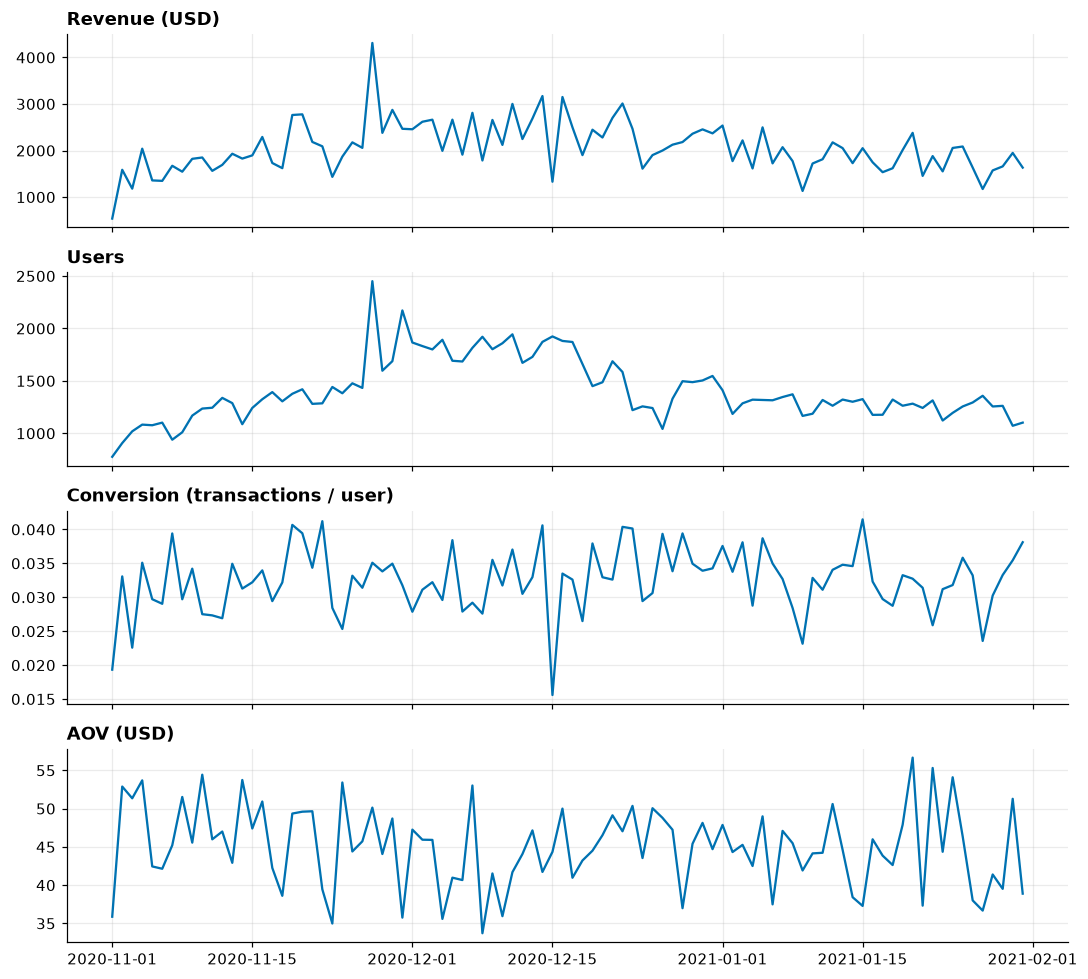

In [2]:
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, col, title in zip(axes, ["revenue_usd", "users", "conversion", "aov"],
                          ["Revenue (USD)", "Users", "Conversion (transactions / user)", "AOV (USD)"], strict=True):
    ax.plot(daily["date"], daily[col], color=PALETTE[0])
    ax.set_title(title, loc="left")
fig.tight_layout()
save(fig, "04_tree_over_time")

Users carry the seasonal shape (Black Friday, pre-Christmas, the January slump). Conversion is flat
apart from one sharp dip in mid-December. AOV is noisy day to day because about 45 orders a day is a
small sample.

## Which node drives each day's change?

In [3]:
contrib = dod[["date", "revenue_change", "users", "conversion", "aov"]].copy()
share_abs = contrib[["users", "conversion", "aov"]].abs()
contrib["main_driver"] = share_abs.idxmax(axis=1)
contrib.loc[contrib["revenue_change"].abs().nlargest(10).index].sort_values("date")

,date,revenue_change,users,conversion,aov,main_driver
0,2020-11-02,"1,048.360",151.257,520.858,376.246,conversion
17,2020-11-19,"1,142.330",115.040,501.204,526.086,aov
25,2020-11-27,"2,253.890","1,635.331",338.077,280.482,users
26,2020-11-28,"-1,931.970","-1,392.363",-120.245,-419.363,users
35,2020-12-07,898.820,173.303,106.856,618.661,aov
36,2020-12-08,"-1,023.100",128.281,-128.281,"-1,023.100",aov
43,2020-12-15,"-1,840.750",58.065,"-2,027.978",129.163,conversion
44,2020-12-16,"1,819.520",-47.717,"1,614.041",253.196,conversion
64,2021-01-05,883.440,-4.603,600.356,287.688,conversion
80,2021-01-21,-924.390,-61.059,-78.264,-785.068,aov


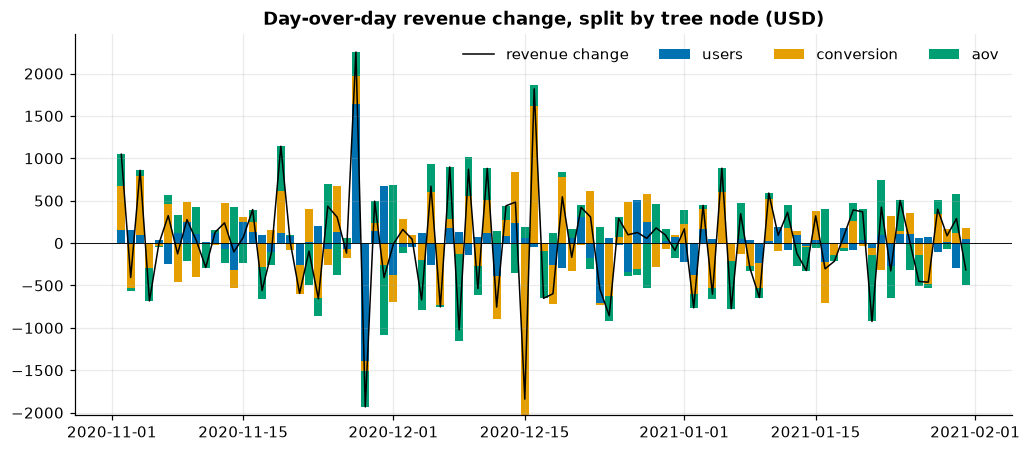

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.5))
bottom_pos = np.zeros(len(dod))
bottom_neg = np.zeros(len(dod))
for col, color in zip(["users", "conversion", "aov"], PALETTE, strict=False):
    vals = dod[col].to_numpy()
    ax.bar(dod["date"], np.where(vals > 0, vals, 0), bottom=bottom_pos, color=color, label=col, width=0.85)
    ax.bar(dod["date"], np.where(vals < 0, vals, 0), bottom=bottom_neg, color=color, width=0.85)
    bottom_pos += np.where(vals > 0, vals, 0)
    bottom_neg += np.where(vals < 0, vals, 0)
ax.plot(dod["date"], dod["revenue_change"], color="black", lw=1, label="revenue change")
ax.axhline(0, color="black", lw=0.6)
ax.set_title("Day-over-day revenue change, split by tree node (USD)")
ax.legend(ncols=4)
save(fig, "04_dod_contributions")

In [5]:
drivers = contrib.assign(abs_change=contrib["revenue_change"].abs())
summary = drivers.groupby("main_driver").agg(days=("date", "count"), mean_abs_change=("abs_change", "mean"))
summary["share_of_days"] = summary["days"] / summary["days"].sum()
summary

,days,mean_abs_change,share_of_days
main_driver,,,
aov,36,410.386,0.396
conversion,44,496.067,0.484
users,11,608.245,0.121


Across all days, AOV and conversion noise drive most day-over-day moves. That's the trouble with
day-over-day comparisons on about 45 orders a day: most moves are noise. Notebook 05 adds a
seasonal baseline and a robust threshold to separate signal from it.

## Case 1 · 2020-12-15: revenue fell 58%

In [6]:
d = daily.set_index(daily["date"].dt.strftime("%Y-%m-%d"))
tree_1215 = M.tree_frame(d.loc["2020-12-14"], d.loc["2020-12-15"])
tree_1215

,node,before,after,pct_change,contribution_usd
0,revenue,"3,171.210","1,330.460",-0.580,"-1,840.750"
1,users,"1,872.000","1,924.000",0.028,58.065
2,new users,"1,167.000","1,203.000",0.031,40.199
3,returning users,705.000,721.000,0.023,17.866
4,conversion (transactions / user),0.041,0.016,-0.616,"-2,027.978"
5,sessions / user,1.069,1.073,0.003,6.570
6,transactions / session,0.038,0.015,-0.617,"-2,034.548"
7,AOV,41.726,44.349,0.063,129.163
8,items / transaction,2.395,2.400,0.002,4.653
9,revenue / item,17.424,18.479,0.061,124.510


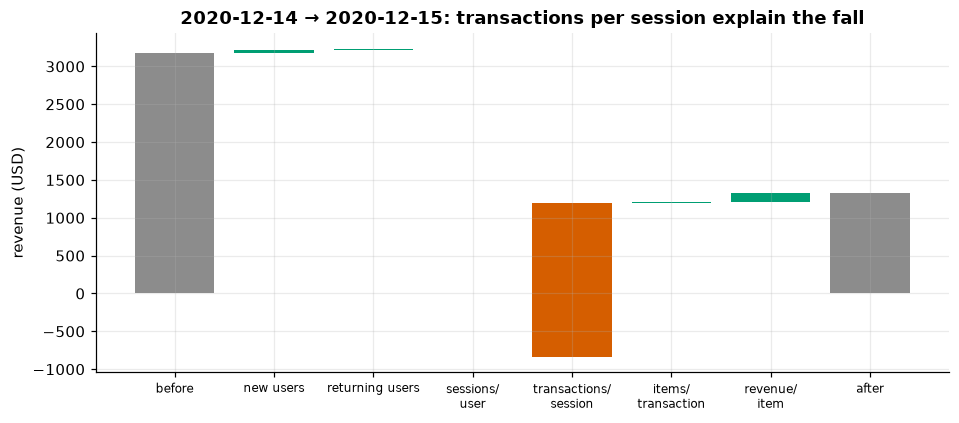

In [7]:
def waterfall(tree: pd.DataFrame, title: str, name: str) -> None:
    leaves = tree[tree["node"].str.startswith("        ")]
    labels = leaves["node"].str.strip().tolist()
    vals = leaves["contribution_usd"].to_numpy()
    start = tree["before"].iloc[0]
    fig, ax = plt.subplots(figsize=(10, 4))
    running = start
    ax.bar("before", start, color=NEUTRAL)
    for lab, v in zip(labels, vals, strict=True):
        ax.bar(lab.replace(" / ", "/\n"), v, bottom=running if v >= 0 else running + v,
               color=PALETTE[2] if v >= 0 else PALETTE[5])
        running += v
    ax.bar("after", tree["after"].iloc[0], color=NEUTRAL)
    ax.set_ylabel("revenue (USD)")
    ax.set_title(title)
    plt.setp(ax.get_xticklabels(), fontsize=8)
    save(fig, name)


waterfall(tree_1215, "2020-12-14 → 2020-12-15: transactions per session explain the fall", "04_waterfall_1215")

Traffic was normal (users +3%) and baskets were normal (AOV +6%). **Transactions per session fell
62%**, and that one leaf accounts for −$2,035 of the −$1,841 change. People came and shopped but did
not complete purchases, so something broke in checkout. Notebook 05 confirms it's an anomaly and
drills into device and funnel step.

## Case 2 · Black Friday, 2020-11-27

In [8]:
tree_bf = M.tree_frame(d.loc["2020-11-26"], d.loc["2020-11-27"])
tree_bf

,node,before,after,pct_change,contribution_usd
0,revenue,"2,057.610","4,311.500",1.095,"2,253.890"
1,users,"1,433.000","2,451.000",0.710,"1,635.331"
2,new users,917.000,"1,939.000",1.115,"1,641.757"
3,returning users,516.000,512.000,-0.008,-6.426
4,conversion (transactions / user),0.031,0.035,0.117,338.077
5,sessions / user,1.060,1.076,0.015,46.443
6,transactions / session,0.030,0.033,0.100,291.634
7,AOV,45.725,50.134,0.096,280.482
8,items / transaction,2.178,2.628,0.207,572.453
9,revenue / item,20.996,19.077,-0.091,-291.971


Black Friday more than doubled revenue, and the users node explains about 73% of it: a traffic
event, not a conversion change. A marketing team that read it as "the site converted better on
Black Friday" would be wrong.

## Does week-over-week help?

In [9]:
wow = M.daily_decomposition(daily, lag=7)
pd.DataFrame({
    "day-over-day": dod[["users", "conversion", "aov"]].abs().mean(),
    "week-over-week": wow[["users", "conversion", "aov"]].abs().mean(),
}).rename_axis("mean absolute contribution (USD)")

,day-over-day,week-over-week
mean absolute contribution (USD),,
users,173.541,252.093
conversion,317.009,333.551
aov,270.820,279.120


No. Week-over-week moves are as large as day-over-day ones, and larger for users, because a 7-day
gap also picks up the holiday trend. The weekday cycle here is mild, so it isn't the main source of
noise. The noise is sampling: conversion and AOV rest on about 45 orders a day. Comparing two single
days, whichever two you pick, can't separate that noise from a real change.

## Period view: first half of December vs January

In [10]:
dec = M.period_totals(daily, "2020-12-01", "2020-12-14")
jan = M.period_totals(daily, "2021-01-04", "2021-01-17")
M.tree_frame(dec, jan)

,node,before,after,pct_change,contribution_usd
0,revenue,"34,790.790","25,641.350",-0.263,"-9,149.440"
1,users,"25,381.000","17,908.000",-0.294,"-10,456.940"
2,new users,"15,541.000","10,176.000",-0.345,"-7,507.223"
3,returning users,"9,840.000","7,732.000",-0.214,"-2,949.716"
4,conversion (transactions / user),0.032,0.033,0.015,433.979
5,sessions / user,1.071,1.071,-0.000,-3.063
6,transactions / session,0.030,0.031,0.015,437.043
7,AOV,42.428,43.682,0.030,873.520
8,items / transaction,2.298,2.305,0.003,96.149
9,revenue / item,18.466,18.951,0.026,777.372


Two comparable 14-day windows: January revenue is down mostly through users (the post-holiday
slump), while conversion and AOV hold. The fix there is acquisition, not the site.

## Takeaways

1. The tree turns "revenue is down" into one named leaf. On Dec 15 that leaf is transactions per
   session, which points at checkout, not marketing.
2. Peaks and slumps are traffic (users); conversion is stable except on the incident day.
3. Single-day comparisons (day over day or week over week) are mostly noise at this volume. Pair
   the tree with anomaly detection (a seasonal baseline plus a robust threshold, notebook 05) before
   acting on a move. Then use the tree to explain the moves that pass.